# Sobre árboles de decisión

Comenzaremos revisando algunos conceptos básicos sobre el funcionamiento de los árboles de decisión. A medida que avancemos en las clases, exploraremos sus diversas características y desafíos, con el objetivo de comprender por qué, en problemas de modelado de datos tabulares, siguen siendo el estado del arte, superando incluso a los modelos más complejos de redes neuronales.



Recomendamos chusmear esta hermosa visualización de cómo funciona un árbol de decisión.

[Cómo funciona un árbol de decisión](http://www.r2d3.us/visual-intro-to-machine-learning-part-1/)

Y luego empezaremos a trabajar con nuestro conjunto de datos para *tratar* de modelar uno. Para eso, debemos iniciar el entorno

## Setup

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree,  _tree


In [71]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Variables importantes

In [16]:
dataset_path = '/content/drive/MyDrive/DMEyF/2026/notebooks/data/'
dataset_file = 'competencia_01.csv'

ganancia_acierto = 1_072_500
costo_estimulo = 27_500

In [17]:
import pandas as pd
check = pd.read_csv(dataset_path + 'competencia_01.csv')
print(check.shape)
print(check['clase_ternaria'].value_counts(dropna=False))

/tmp/ipykernel_4026/2857182448.py:2: DtypeWarning: Columns (155) have mixed types. Specify dtype option on import or set low_memory=False.
  check = pd.read_csv(dataset_path + 'competencia_01.csv')


(983061, 156)
clase_ternaria
CONTINUA    645999
NaN         327892
BAJA+1        5103
BAJA+2        4067
Name: count, dtype: int64


Cargamos el **dataset**, vamos a trabajar en esta ocasión solo con un periodo: **202104**.

Algo que va a generar algo de confusión es que no separemos con **Train / Test** en esta ocasión.

**NO ENTRE EN PÁNICO**, en esta cursada se le dedicará mucho tiempo a entender y combatir el problema del overfitting. Pero no hoy.

In [18]:
data = pd.read_csv(dataset_path+dataset_file)
data = data[data['foto_mes'] == 202104]

X = data.drop('clase_ternaria', axis=1)
y = data['clase_ternaria']


/tmp/ipykernel_4026/2916171371.py:1: DtypeWarning: Columns (155) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(dataset_path+dataset_file)


Veamos que porcentaje ocupa de nuestro dataset, el target que queremos predecir

In [19]:
print(data.shape)
print(data['foto_mes'].unique())
print(data['clase_ternaria'].unique())

(163284, 156)
[202104]
['CONTINUA' 'BAJA+2' 'BAJA+1']


In [20]:
data['clase_ternaria'].value_counts(normalize=True)*100

,proportion
clase_ternaria,
CONTINUA,98.712060
BAJA+2,0.697558
BAJA+1,0.590382


* **¿Había trabajado con un target tan poco representativo?**
* **¿Cree que esto es algo común o tan solo una rareza?**

## Primer árbol
Con nuestros datos ya cargados en **memoria**, podemos dedicarnos a generar nuestro primer árbol

### Párametros

(gentileza de chat-gpt en un 90%)

El **DecisionTreeClassifier** en scikit-learn tiene varios parámetros que controlan cómo se construye el árbol de decisión. A continuación te explico los más importantes:

1. **criterion**: Este parámetro define la función que se usa para medir la calidad de una división (split). Las opciones principales son:

    * **gini** (predeterminado): Utiliza el índice de Gini, que mide la impureza de las particiones. Un valor de Gini más bajo significa que una partición es más pura.
    * **entropy**: Utiliza la entropía de la información, relacionada con el concepto de ganancia de información. Se enfoca en reducir la incertidumbre en las particiones.

2. **max_depth**: Controla la profundidad máxima del árbol.

3. **min_samples_split**: Especifica el número mínimo de muestras que un nodo debe tener para poder dividirse.

4. **min_samples_leaf**: Define el número mínimo de muestras que debe tener una hoja (nodo final).

5. **max_features**: Indica el número máximo de características que el modelo debe considerar para hacer la mejor división.

6. **max_leaf_nodes**: Especifica el número máximo de nodos hoja que el árbol puede tener.

7. **random_state**: Fija la semilla utilizada por el generador de números aleatorios, lo que garantiza que los resultados del entrenamiento sean reproducibles.

8. **ccp_alpha**: Parámetro de complejidad de poda mínima, utilizado para la poda de árboles de decisión después de que se hayan construido. Un valor más alto lleva a árboles más pequeños.

 **EN LA CURSADA CREEMOS QUE LA INTELIGENCIA DEL ALUMNO CORRELACIONA DE FORMA NEGATIVA A VALOR QUE SETEA ESTE PARÁMETRO**

Queda de tarea para el alumnado jugar con algunas parametrías. Usaremos a continuación una simple

### Modelo

In [21]:
model = DecisionTreeClassifier(criterion='gini',
                               random_state=17,
                               min_samples_split=80,
                               min_samples_leaf=1,
                               max_depth=5)

model.fit(X, y)

DecisionTreeClassifier(max_depth=5, min_samples_split=80, random_state=17)

### Visualización

Todo es mucho más bonito si tiene colores

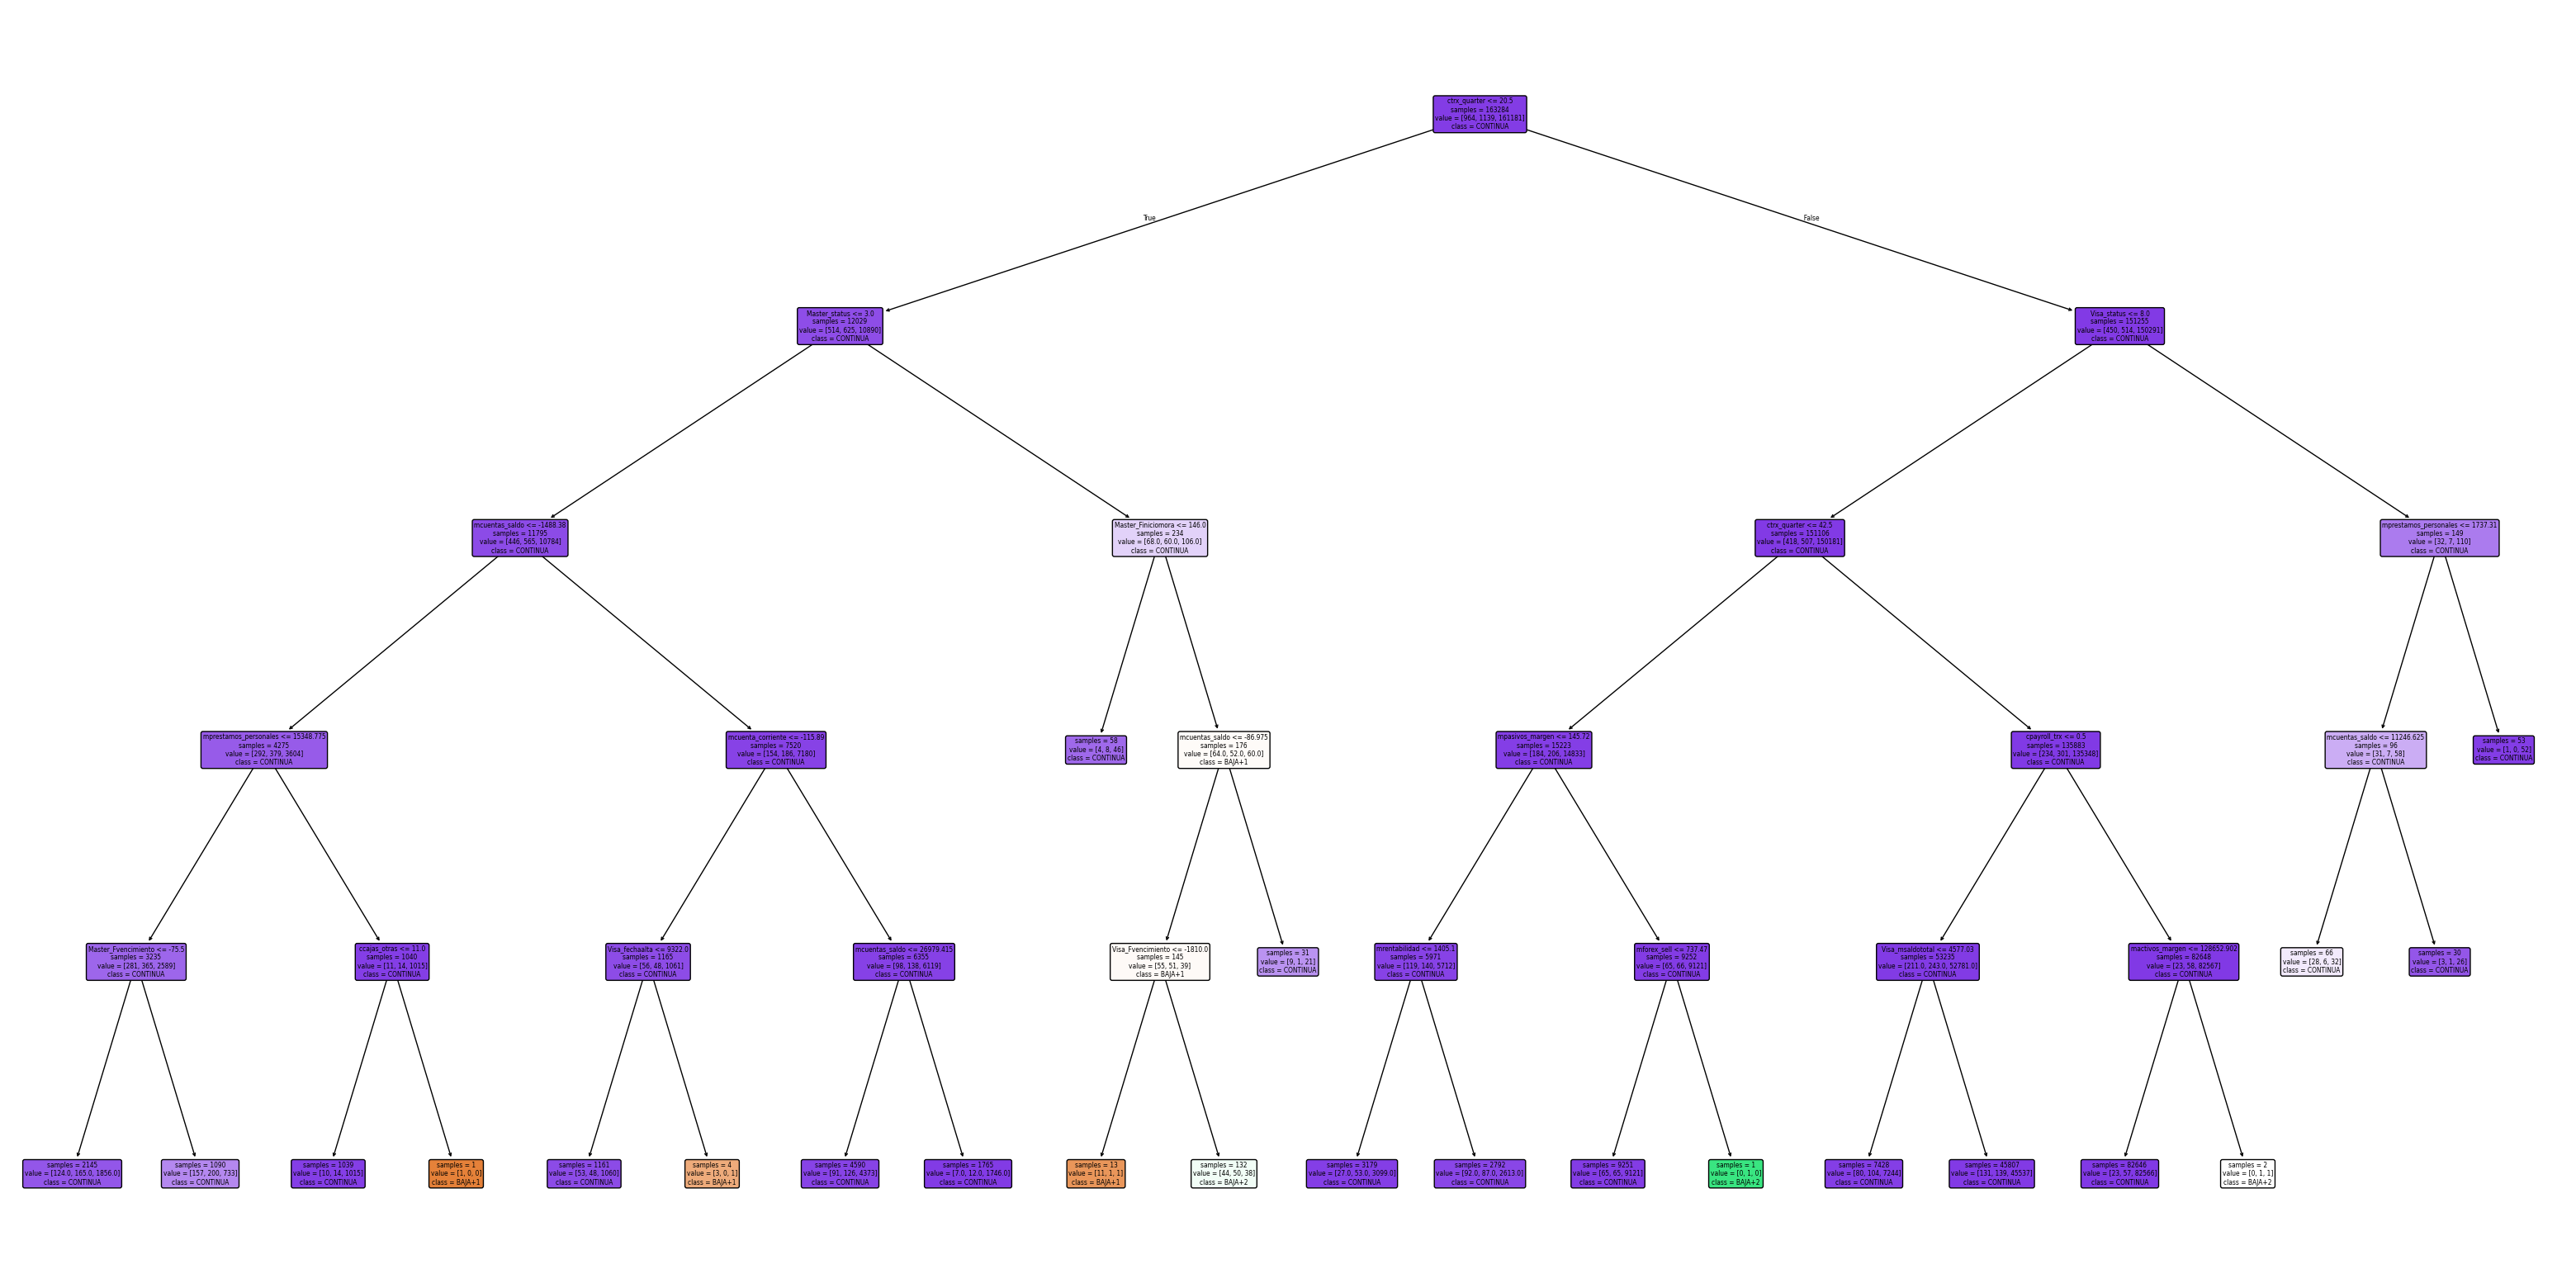

In [22]:
plt.figure(figsize=(40,20))
plot_tree(model, feature_names=X.columns, filled=True, class_names=model.classes_, rounded=True, impurity=False) #,  proportion=True)
plt.show()

### Midiendo el modelo

Mirando tan solo la visualización

* **¿Qué tan bien performó el modelo?**
* **¿Qué tan bien detectó los CONTINUA?**
* **¿Qué tan bien detectó los BAJA+2?**

Para meter manos en la masa, vamos a llevar las hojas del modelo a una tabla, para esto haremos uso de una función auxiliar

In [23]:
def get_leaf_info(tree):
    tree_ = tree.tree_
    class_names = tree.classes_
    leaf_info = []
    for i in range(tree_.node_count):
        if tree_.children_left[i] == _tree.TREE_LEAF:
            class_counts = tree_.value[i][0] * int(tree_.n_node_samples[i])
            predicted_class_index = class_counts.argmax()
            predicted_class = class_names[predicted_class_index]
            row = {
                'Node': i,
                'Samples': int(tree_.n_node_samples[i]),
                'Predicted Class': predicted_class
            }
            for j, class_name in enumerate(class_names):
                row[class_name] = int(class_counts[j])
            leaf_info.append(row)
    return pd.DataFrame(leaf_info)

leaf_df = get_leaf_info(model)
leaf_df


,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA
0,5,2145,CONTINUA,124,165,1856
1,6,1090,CONTINUA,157,200,733
2,8,1039,CONTINUA,10,14,1015
3,9,1,BAJA+1,1,0,0
4,12,1161,CONTINUA,53,48,1060
5,13,4,BAJA+1,3,0,1
6,15,4590,CONTINUA,91,126,4373
7,16,1765,CONTINUA,7,12,1746
8,18,58,CONTINUA,4,8,46
9,21,13,BAJA+1,11,1,1


Ahora en el dataset **leaf_ds** tenemos cada nodo terminal (hoja).

Vemos que según el modelo, no deberíamos mandar ningún estímulo, dado que no detectó ningún **BAJA+2**. Sin embargo dudaremos de esto y veremos cuanta plata nos hubiera dejado cada hoja, si enviáramos a los clientes que cayeron en esta.


Lo que importa es si en esa hoja hay suficiente proporción de BAJA+2 como para que, en promedio, mandarles estímulo a todos los de esa hoja sea rentable — aunque la mayoría termine siendo CONTINUA y "se pierda plata" con esos.

usar solo Predicted Class te hace descartar clientes rentables porque exige que BAJA+2 sea mayoría absoluta en la hoja


Predicted Class responde una pregunta distinta a la que en realidad te importa. Responde: "¿cuál es la clase más común en esta hoja?" — una pregunta de clasificación pura, sin ningún peso económico de por medio. Trata como si costara lo mismo equivocarse con un BAJA+1 que con un BAJA+2 que con un CONTINUA, y por eso pierde ante la clase que simplemente tiene más volumen (CONTINUA, que es el 98,7% del dataset).

La pregunta que en realidad le interesa al banco es otra: "¿mandarle estímulo a todo este grupo de clientes me deja ganancia positiva o negativa, dado que acertar vale $1.072.500 y equivocarme cuesta $27.500?" — esa es una pregunta de negocio, y la resuelve la probabilidad de BAJA+2 comparada contra el punto de corte (0,025), no la mayoría.

Y la razón de fondo por la que estas dos preguntas dan respuestas distintas es la asimetría de costos: como acertar vale ~39 veces más que lo que cuesta una campaña desperdiciada, no hace falta que BAJA+2 sea mayoría para que convenga apostarle a todo el pool — con que sea ~1 de cada 40 (2,5%) ya empata, y de ahí para arriba, gana.

Por eso en toda la materia (y en la Última Competencia en diciembre) vas a trabajar siempre con la ganancia en pesos como métrica, y no con accuracy ni con la clase que "gana por mayoría" — porque esta última te lleva a decisiones que parecen razonables en el papel pero le hacen perder plata al banco.

In [24]:
leaf_df["ganancia"] = ganancia_acierto*leaf_df["BAJA+2"] - costo_estimulo*leaf_df["BAJA+1"] + -costo_estimulo*leaf_df["CONTINUA"]
leaf_df.sort_values("ganancia", ascending=False, inplace=True)
leaf_df

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia
1,6,1090,CONTINUA,157,200,733,190025000
0,5,2145,CONTINUA,124,165,1856,122512500
10,22,132,BAJA+2,44,50,38,51370000
4,12,1161,CONTINUA,53,48,1060,20872500
13,29,2792,CONTINUA,91,87,2613,18947500
6,15,4590,CONTINUA,91,126,4373,12375000
8,18,58,CONTINUA,4,8,46,7205000
20,42,66,CONTINUA,28,6,32,4785000
15,32,1,BAJA+2,0,1,0,1072500
19,39,2,BAJA+2,0,1,1,1045000


Vaya! no son pocos las hojas que hubieran dado ganancia positiva, y todas a su vez estuvieron mal clasificadas por el modelo.

Veamos de calcular la probabilidad de **BAJA+2** por cada hoja

In [25]:
leaf_df["prob_baja_2"] = leaf_df["BAJA+2"]/leaf_df["Samples"]
leaf_df.sort_values("prob_baja_2", ascending=False, inplace=True)
leaf_df

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia,prob_baja_2
15,32,1,BAJA+2,0,1,0,1072500,1.000000
19,39,2,BAJA+2,0,1,1,1045000,0.500000
10,22,132,BAJA+2,44,50,38,51370000,0.378788
1,6,1090,CONTINUA,157,200,733,190025000,0.183486
8,18,58,CONTINUA,4,8,46,7205000,0.137931
20,42,66,CONTINUA,28,6,32,4785000,0.090909
0,5,2145,CONTINUA,124,165,1856,122512500,0.076923
9,21,13,BAJA+1,11,1,1,742500,0.076923
4,12,1161,CONTINUA,53,48,1060,20872500,0.041344
21,43,30,CONTINUA,3,1,26,275000,0.033333



No es que "los valores de proporción menor a 0,025 dan pérdida" per se sin más — es más específico: el umbral 0,025 es el punto exacto donde la ganancia de esa hoja pasa de negativa a positiva (matemáticamente, es el punto de equilibrio). Por debajo, pierde; en o por encima, gana. No son dos hechos separados — el umbral se deriva de la fórmula de ganancia, no es una regla aparte que coincide.

Pero la pregunta que te hice era otra, más específica: ¿por qué era esperable encontrar muchas hojas con proporción > 0,025 que el árbol de todas formas clasificó como CONTINUA (o sea, "mal clasificadas")? Pensalo así: el árbol usa gini (o el criterio por defecto) para decidir sus cortes — ¿gini "sabe" algo sobre el número 0,025 o sobre los pesos de $1.072.500 y $27.500? ¿El árbol fue construido pensando en maximizar ganancia, o en otra cosa?

Gini mide pureza así que esos árboles eran más puros en la clase que predijeorn supongo

Sí, ahí está el eslabón que faltaba — bien.

Exacto: gini no sabe nada de plata. Es un criterio puramente estadístico que mide qué tan "revuelta" está una hoja entre las 3 clases, sin ponderar que equivocarse con un BAJA+2 cuesta $1.072.500 de oportunidad perdida y equivocarse con un CONTINUA cuesta apenas $27.500. Para gini, las tres clases valen lo mismo — sus 39x de diferencia en el mundo real le son invisibles.

Por eso pasa lo que ves en la tabla: el árbol arma cortes que maximizan pureza estadística (por eso casi todas las hojas terminan siendo mayoría CONTINUA, la clase más fácil de aislar), pero nunca se le pidió que optimizara ganancia en pesos. El resultado es exactamente lo que describís: hojas "puras" según gini que, al pasarlas por la fórmula de negocio, resultan rentables aunque el árbol nunca las haya reconocido como tal.

Esa desconexión — entre el criterio que usa el algoritmo para construirse (gini/entropía) y la métrica real que te importa (ganancia) — es probablemente la idea más importante de toda la materia, y la vas a ver reaparecer constantemente: en el punto de corte, en cómo se elige cp en rpart, en por qué la cátedra insiste tanto en medir ganancia y no AUC/accuracy.





Finalmente calculemos la ganancia acumulada para cada posible punto de corte:

In [26]:
leaf_df['gan_acumulada'] = leaf_df['ganancia'].cumsum()
leaf_df

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia,prob_baja_2,gan_acumulada
15,32,1,BAJA+2,0,1,0,1072500,1.000000,1072500
19,39,2,BAJA+2,0,1,1,1045000,0.500000,2117500
10,22,132,BAJA+2,44,50,38,51370000,0.378788,53487500
1,6,1090,CONTINUA,157,200,733,190025000,0.183486,243512500
8,18,58,CONTINUA,4,8,46,7205000,0.137931,250717500
20,42,66,CONTINUA,28,6,32,4785000,0.090909,255502500
0,5,2145,CONTINUA,124,165,1856,122512500,0.076923,378015000
9,21,13,BAJA+1,11,1,1,742500,0.076923,378757500
4,12,1161,CONTINUA,53,48,1060,20872500,0.041344,399630000
21,43,30,CONTINUA,3,1,26,275000,0.033333,399905000


* **¿Cuál es la ganancia máxima que puede obtener con este modelo?** 43147500
* **¿Nota alguna relación con la probabilidad de corte óptima discutida en la clase anterior?**
si, el 0,025

### Matrices de Confusión

Todos ya sabemos que es son las matrices de confusión y como usando los valores de la misma, podemos  [calcular varios estadísticos](https://en.wikipedia.org/wiki/Confusion_matrix#Table_of_confusion)

Una diferencia a lo trabajado hasta ahora en la maestría, es que por cada modelo no vamos a generar 1 matriz de confusión, sino múltiples, 1 por cada punto de corte.

Para eso tenemos que proceder:
* Agrupar los buenos y los malos, ya que la mayoría de los indicadores son binarios
* Calcular los valores: **TP, TN, FP y FN**

In [27]:
leaf_df["evento"] = leaf_df["BAJA+2"]
leaf_df["no_evento"] = leaf_df["CONTINUA"] + leaf_df["BAJA+1"]

leaf_df["evento_acum"] = leaf_df["evento"].cumsum()
leaf_df["no_evento_acum"] = leaf_df["no_evento"].cumsum()

total_evento = leaf_df["evento"].sum()
total_noevento = leaf_df["no_evento"].sum()

leaf_df['evento_restantes'] = total_evento - leaf_df["evento_acum"]
leaf_df['noevento_restantes'] = total_noevento - leaf_df["no_evento_acum"]

leaf_df["TP"] = leaf_df["evento_acum"]
leaf_df["TN"] = leaf_df["noevento_restantes"]
leaf_df["FP"] = leaf_df["no_evento_acum"]
leaf_df["FN"] = leaf_df["evento_restantes"]

leaf_df

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia,prob_baja_2,gan_acumulada,evento,no_evento,evento_acum,no_evento_acum,evento_restantes,noevento_restantes,TP,TN,FP,FN
15,32,1,BAJA+2,0,1,0,1072500,1.000000,1072500,1,0,1,0,1138,162144,1,162144,0,1138
19,39,2,BAJA+2,0,1,1,1045000,0.500000,2117500,1,1,2,1,1137,162143,2,162143,1,1137
10,22,132,BAJA+2,44,50,38,51370000,0.378788,53487500,50,82,52,83,1087,162061,52,162061,83,1087
1,6,1090,CONTINUA,157,200,733,190025000,0.183486,243512500,200,890,252,973,887,161171,252,161171,973,887
8,18,58,CONTINUA,4,8,46,7205000,0.137931,250717500,8,50,260,1023,879,161121,260,161121,1023,879
20,42,66,CONTINUA,28,6,32,4785000,0.090909,255502500,6,60,266,1083,873,161061,266,161061,1083,873
0,5,2145,CONTINUA,124,165,1856,122512500,0.076923,378015000,165,1980,431,3063,708,159081,431,159081,3063,708
9,21,13,BAJA+1,11,1,1,742500,0.076923,378757500,1,12,432,3075,707,159069,432,159069,3075,707
4,12,1161,CONTINUA,53,48,1060,20872500,0.041344,399630000,48,1113,480,4188,659,157956,480,157956,4188,659
21,43,30,CONTINUA,3,1,26,275000,0.033333,399905000,1,29,481,4217,658,157927,481,157927,4217,658


Nos quedamos con una tabla reducida

In [28]:
leaf2_df = leaf_df[["prob_baja_2", "TP", "TN", "FP", "FN"]]
leaf2_df.sort_values("prob_baja_2", ascending=False, inplace=True)
leaf2_df

/tmp/ipykernel_4026/252966762.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  leaf2_df.sort_values("prob_baja_2", ascending=False, inplace=True)


,prob_baja_2,TP,TN,FP,FN
15,1.000000,1,162144,0,1138
19,0.500000,2,162143,1,1137
10,0.378788,52,162061,83,1087
1,0.183486,252,161171,973,887
8,0.137931,260,161121,1023,879
20,0.090909,266,161061,1083,873
0,0.076923,431,159081,3063,708
9,0.076923,432,159069,3075,707
4,0.041344,480,157956,4188,659
21,0.033333,481,157927,4217,658


Con esta tabla podemos nos solo calcular los indicadores clásicos, sino que podemos hacer por cada punto de corte, dibujar la curva y establecer cuál es el optimo punto de corte que máximiza el métrica.



#### curva ROC

La curva ROC (Receiver Operating Characteristic) es una herramienta gráfica utilizada en ciencia de datos para evaluar el rendimiento de un modelo de clasificación binaria. Es particularmente útil para entender  el trade-off entre cuánto podemos ganar, en función de cuanto estamos dispuestos a perder.

Se dibuja como **Tasa de Falsos Positivos** contra **Tasa de Verdaderos Positivos**


/tmp/ipykernel_4026/2773130844.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  leaf2_df['TPR'] = leaf2_df['TP'] / (leaf2_df['TP'] + leaf2_df['FN'])
/tmp/ipykernel_4026/2773130844.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  leaf2_df['FPR'] = leaf2_df['FP'] / (leaf2_df['FP'] + leaf2_df['TN'])


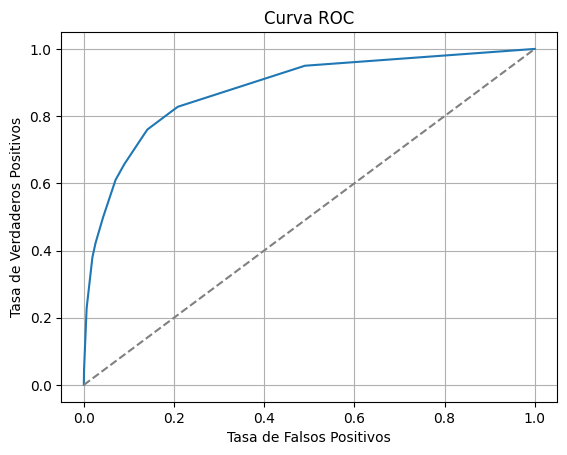

In [29]:
leaf2_df['TPR'] = leaf2_df['TP'] / (leaf2_df['TP'] + leaf2_df['FN'])
leaf2_df['FPR'] = leaf2_df['FP'] / (leaf2_df['FP'] + leaf2_df['TN'])

sns.lineplot(x='FPR', y='TPR', data=leaf2_df)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.grid(True)
plt.show()

# Nota: Es probable que los valores de FPR y TPR esten lejos del [0,0] y [1,1]
# si ese es su caso, debe agregarlos a mano a la tabla

* La línea de identidad indica el comportamiento de un clasificador que no tiene ninguna habilidad para distinguir entre las clases positivas y negativas.
* Es una métrica independiente de la distribución de clases: La curva ROC no depende de la distribución de las clases en los datos (balance de clases), lo que la hace útil en situaciones donde las clases están desbalanceadas.
* Es una evaluación global del modelo: La curva ROC proporciona una visión más completa del rendimiento del modelo.

No todo son rosas, si queremos comparar 2 modelos, mirar curvas puede ser complejo. Por esto mismo, se suele calcular la métrica **AUC** (Area Under the Curve) como un estatístico de la calidad del modelo.

dos árboles distintos podrían dibujar exactamente la misma curva ROC (mismo AUC, misma forma), pero si uno concentra sus errores en hojas chiquitas y el otro en hojas gigantes, el costo en pesos de sus FP es completamente distinto — y la ROC no lo distingue, porque solo mira proporciones.

In [31]:
np.trapz(leaf2_df['TPR'], leaf2_df['FPR']) # calcula el área de bajo de la curva

/tmp/ipykernel_4026/3154154329.py:1: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  np.trapz(leaf2_df['TPR'], leaf2_df['FPR']) # calcula el área de bajo de la curva


np.float64(0.8801650372930736)

In [72]:
# Usando la función recomendada para evitar la advertencia de desaprobación
np.trapezoid(leaf2_df['TPR'], leaf2_df['FPR'])

np.float64(0.8801650372930736)

* AUC = 1: El modelo clasifica perfectamente todas las instancias. Más cerca de 1 se encuentra el indicador, mejor.
* AUC = 0.5: El modelo no tiene capacidad discriminativa; su rendimiento es equivalente a realizar una clasificación aleatoria.
* AUC < 0.5: Indica un rendimiento peor que una clasificación aleatoria (dale vuelta a la clase).
* Más de una curva puede tener la misma AUC, se suele elegir a la más empinada

### Tarea
* Cambie los parámetros del modelo y vea los impactos en cada una de las métricas.
 * ¿Cuál fue el modelo que dió más ganancia económica? ¿El peor?
 * ¿Cuál fue el modelo que dió mayor AUC? ¿El peor?
* Calcule, dibuje y encuentre el punto de corte óptimo para:
 * Accuracy
 * Sensibilidad
 * Especificidad
 * F1-Score

#### Tarea prueba modelo 2
Se cambia el criterion a entropy




In [33]:
model2 = DecisionTreeClassifier(criterion='entropy',
                               random_state=17,
                               min_samples_split=80,
                               min_samples_leaf=1,
                               max_depth=5)

model2.fit(X, y)

DecisionTreeClassifier(criterion='entropy', max_depth=5, min_samples_split=80,
                       random_state=17)

In [34]:
def get_leaf_info(tree):
    tree_ = tree.tree_
    class_names = tree.classes_
    leaf_info = []
    for i in range(tree_.node_count):
        if tree_.children_left[i] == _tree.TREE_LEAF:
            class_counts = tree_.value[i][0] * int(tree_.n_node_samples[i])
            predicted_class_index = class_counts.argmax()
            predicted_class = class_names[predicted_class_index]
            row = {
                'Node': i,
                'Samples': int(tree_.n_node_samples[i]),
                'Predicted Class': predicted_class
            }
            for j, class_name in enumerate(class_names):
                row[class_name] = int(class_counts[j])
            leaf_info.append(row)
    return pd.DataFrame(leaf_info)

leaf_df2 = get_leaf_info(model2)
leaf_df2

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA
0,5,2089,CONTINUA,149,194,1746
1,6,1977,CONTINUA,66,53,1858
2,8,1178,CONTINUA,144,214,820
3,9,117,BAJA+1,57,27,33
4,12,783,CONTINUA,13,16,754
5,13,425,CONTINUA,0,3,422
6,14,432,CONTINUA,0,0,432
7,18,5510,CONTINUA,185,198,5127
8,19,1105,CONTINUA,5,6,1094
9,21,1,BAJA+1,1,0,0


In [35]:
leaf_df2["ganancia"] = ganancia_acierto*leaf_df2["BAJA+2"] - costo_estimulo*leaf_df2["BAJA+1"] + -costo_estimulo*leaf_df2["CONTINUA"]
leaf_df2.sort_values("ganancia", ascending=False, inplace=True)
leaf_df2

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia
2,8,1178,CONTINUA,144,214,820,203005000
0,5,2089,CONTINUA,149,194,1746,155952500
7,18,5510,CONTINUA,185,198,5127,66275000
3,9,117,BAJA+1,57,27,33,26482500
1,6,1977,CONTINUA,66,53,1858,3932500
17,36,62,CONTINUA,21,4,37,2695000
14,29,80,CONTINUA,0,4,76,2200000
25,51,47,CONTINUA,5,2,39,935000
9,21,1,BAJA+1,1,0,0,-27500
29,58,246,CONTINUA,4,4,238,-2365000


In [36]:
leaf_df2["prob_baja_2"] = leaf_df2["BAJA+2"]/leaf_df2["Samples"]
leaf_df2.sort_values("prob_baja_2", ascending=False, inplace=True)
leaf_df2

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia,prob_baja_2
3,9,117,BAJA+1,57,27,33,26482500,0.230769
2,8,1178,CONTINUA,144,214,820,203005000,0.181664
0,5,2089,CONTINUA,149,194,1746,155952500,0.092867
17,36,62,CONTINUA,21,4,37,2695000,0.064516
14,29,80,CONTINUA,0,4,76,2200000,0.050000
25,51,47,CONTINUA,5,2,39,935000,0.042553
7,18,5510,CONTINUA,185,198,5127,66275000,0.035935
1,6,1977,CONTINUA,66,53,1858,3932500,0.026808
15,34,4722,CONTINUA,82,98,4542,-22055000,0.020754
4,12,783,CONTINUA,13,16,754,-3932500,0.020434


In [37]:
leaf_df2['gan_acumulada'] = leaf_df2['ganancia'].cumsum()
leaf_df2

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia,prob_baja_2,gan_acumulada
3,9,117,BAJA+1,57,27,33,26482500,0.230769,26482500
2,8,1178,CONTINUA,144,214,820,203005000,0.181664,229487500
0,5,2089,CONTINUA,149,194,1746,155952500,0.092867,385440000
17,36,62,CONTINUA,21,4,37,2695000,0.064516,388135000
14,29,80,CONTINUA,0,4,76,2200000,0.050000,390335000
25,51,47,CONTINUA,5,2,39,935000,0.042553,391270000
7,18,5510,CONTINUA,185,198,5127,66275000,0.035935,457545000
1,6,1977,CONTINUA,66,53,1858,3932500,0.026808,461477500
15,34,4722,CONTINUA,82,98,4542,-22055000,0.020754,439422500
4,12,783,CONTINUA,13,16,754,-3932500,0.020434,435490000


In [66]:
leaf_df2["evento"] = leaf_df2["BAJA+2"]
leaf_df2["no_evento"] = leaf_df2["CONTINUA"] + leaf_df2["BAJA+1"]

leaf_df2["evento_acum"] = leaf_df2["evento"].cumsum()
leaf_df2["no_evento_acum"] = leaf_df2["no_evento"].cumsum()

total_evento = leaf_df2["evento"].sum()
total_noevento = leaf_df2["no_evento"].sum()

leaf_df2['evento_restantes'] = total_evento - leaf_df2["evento_acum"]
leaf_df2['noevento_restantes'] = total_noevento - leaf_df2["no_evento_acum"]

leaf_df2["TP"] = leaf_df2["evento_acum"]
leaf_df2["TN"] = leaf_df2["noevento_restantes"]
leaf_df2["FP"] = leaf_df2["no_evento_acum"]
leaf_df2["FN"] = leaf_df2["evento_restantes"]

leaf_df2

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia,prob_baja_2,gan_acumulada,evento,no_evento,evento_acum,no_evento_acum,evento_restantes,noevento_restantes,TP,TN,FP,FN
3,9,117,BAJA+1,57,27,33,26482500,0.230769,26482500,27,90,27,90,1111,162054,27,162054,90,1111
2,8,1178,CONTINUA,144,214,820,203005000,0.181664,229487500,214,964,241,1054,897,161090,241,161090,1054,897
0,5,2089,CONTINUA,149,194,1746,155952500,0.092867,385440000,194,1895,435,2949,703,159195,435,159195,2949,703
17,36,62,CONTINUA,21,4,37,2695000,0.064516,388135000,4,58,439,3007,699,159137,439,159137,3007,699
14,29,80,CONTINUA,0,4,76,2200000,0.050000,390335000,4,76,443,3083,695,159061,443,159061,3083,695
25,51,47,CONTINUA,5,2,39,935000,0.042553,391270000,2,44,445,3127,693,159017,445,159017,3127,693
7,18,5510,CONTINUA,185,198,5127,66275000,0.035935,457545000,198,5312,643,8439,495,153705,643,153705,8439,495
1,6,1977,CONTINUA,66,53,1858,3932500,0.026808,461477500,53,1924,696,10363,442,151781,696,151781,10363,442
15,34,4722,CONTINUA,82,98,4542,-22055000,0.020754,439422500,98,4624,794,14987,344,147157,794,147157,14987,344
4,12,783,CONTINUA,13,16,754,-3932500,0.020434,435490000,16,767,810,15754,328,146390,810,146390,15754,328


In [67]:
leaf2_df2 = leaf_df2[["prob_baja_2", "TP", "TN", "FP", "FN"]]
leaf2_df2.sort_values("prob_baja_2", ascending=False, inplace=True)
leaf2_df2

/tmp/ipykernel_4026/2317540039.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  leaf2_df2.sort_values("prob_baja_2", ascending=False, inplace=True)


,prob_baja_2,TP,TN,FP,FN
3,0.230769,27,162054,90,1111
2,0.181664,241,161090,1054,897
0,0.092867,435,159195,2949,703
17,0.064516,439,159137,3007,699
14,0.050000,443,159061,3083,695
25,0.042553,445,159017,3127,693
7,0.035935,643,153705,8439,495
1,0.026808,696,151781,10363,442
15,0.020754,794,147157,14987,344
4,0.020434,810,146390,15754,328


/tmp/ipykernel_4026/1147183906.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  leaf2_df2['TPR'] = leaf2_df2['TP'] / (leaf2_df2['TP'] + leaf2_df2['FN'])
/tmp/ipykernel_4026/1147183906.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  leaf2_df2['FPR'] = leaf2_df2['FP'] / (leaf2_df2['FP'] + leaf2_df2['TN'])


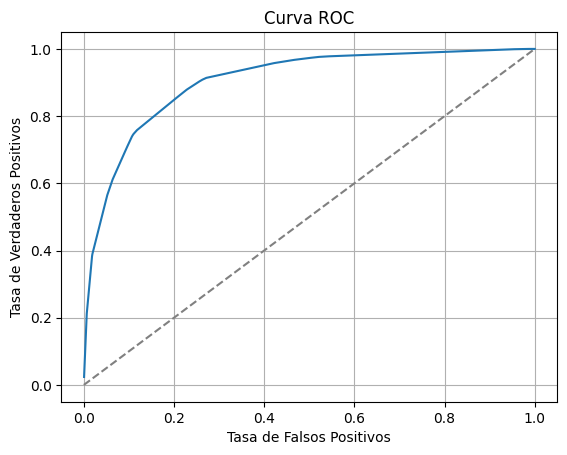

In [68]:
leaf2_df2['TPR'] = leaf2_df2['TP'] / (leaf2_df2['TP'] + leaf2_df2['FN'])
leaf2_df2['FPR'] = leaf2_df2['FP'] / (leaf2_df2['FP'] + leaf2_df2['TN'])

sns.lineplot(x='FPR', y='TPR', data=leaf2_df2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.grid(True)
plt.show()

# Nota: Es probable que los valores de FPR y TPR esten lejos del [0,0] y [1,1]
# si ese es su caso, debe agregarlos a mano a la tabla

In [69]:
leaf2_df2 = leaf_df2[["prob_baja_2", "TP", "TN", "FP", "FN"]].copy()
leaf2_df2.sort_values("prob_baja_2", ascending=False, inplace=True)

leaf2_df2['sensibilidad'] = leaf2_df2['TP'] / (leaf2_df2['TP'] + leaf2_df2['FN'])
leaf2_df2['especificidad'] = leaf2_df2['TN'] / (leaf2_df2['TN'] + leaf2_df2['FP'])
leaf2_df2['accuracy'] = (leaf2_df2['TP'] + leaf2_df2['TN']) / (leaf2_df2['TP'] + leaf2_df2['TN'] + leaf2_df2['FP'] + leaf2_df2['FN'])
leaf2_df2['precision'] = leaf2_df2['TP'] / (leaf2_df2['TP'] + leaf2_df2['FP'])
leaf2_df2['f1'] = 2 * (leaf2_df2['precision'] * leaf2_df2['sensibilidad']) / (leaf2_df2['precision'] + leaf2_df2['sensibilidad'])

print("Máximo accuracy:", leaf2_df2.loc[leaf2_df2['accuracy'].idxmax(), ['prob_baja_2', 'accuracy']].to_dict())
print("Máxima sensibilidad:", leaf2_df2.loc[leaf2_df2['sensibilidad'].idxmax(), ['prob_baja_2', 'sensibilidad']].to_dict())
print("Máxima especificidad:", leaf2_df2.loc[leaf2_df2['especificidad'].idxmax(), ['prob_baja_2', 'especificidad']].to_dict())
print("Máximo F1:", leaf2_df2.loc[leaf2_df2['f1'].idxmax(), ['prob_baja_2', 'f1']].to_dict())

Máximo accuracy: {'prob_baja_2': 0.23076923076923078, 'accuracy': 0.9926446270868804}
Máxima sensibilidad: {'prob_baja_2': 0.00019175455417066154, 'sensibilidad': 1.0}
Máxima especificidad: {'prob_baja_2': 0.23076923076923078, 'especificidad': 0.9994449378330373}
Máximo F1: {'prob_baja_2': 0.18166383701188454, 'f1': 0.19810933004521167}


ninguno de estos 4 cortes óptimos (0,23 / 0,0002 / 0,23 / 0,18) coincide ni de cerca con tu corte real de negocio (0,0274, el que maximizaba ganancia). Cada métrica "optimiza" para un objetivo distinto al que realmente te importa — es la prueba definitiva, con tus propios números, de que ninguna de estas 4 sirve para elegir el punto de corte real de la campaña.

In [73]:
temp_df = leaf2_df2.dropna(subset=['TP', 'TN', 'FP', 'FN']).copy()
temp_df['TPR'] = temp_df['TP'] / (temp_df['TP'] + temp_df['FN'])
temp_df['FPR'] = temp_df['FP'] / (temp_df['FP'] + temp_df['TN'])
np.trapezoid(temp_df['TPR'], temp_df['FPR'])

np.float64(0.9041257301544194)

#### Tarea prueba modelo 3

Se le agrega un ccp_alpha=0.0005 y se compara con el modelo original que por defecto usa ccp_alpha=0.0




ccp_alpha mira cuánto mejora la pureza un split respecto al nodo padre (la ganancia de pureza que aporta esa división puntual). Si esa mejora es grande (el split separa muy bien las clases) → se mantiene, sin importar ccp_alpha.
Si esa mejora es chica, menor al valor de ccp_alpha  → se descarta (se poda), aunque haya ayudado algo. Cuando se poda un split, los dos nodos hijos que hubiera generado desaparecen — se fusionan de vuelta en el nodo padre, que pasa a ser una hoja final en sí mismo. Todos los clientes que iban a terminar separados en esos dos hijos. Util para evitar el overfitting

In [42]:
model3 = DecisionTreeClassifier(criterion='gini',
                               random_state=17,
                               min_samples_split=80,
                               min_samples_leaf=1,
                               max_depth=5,
                              ccp_alpha=0.0005)

model3.fit(X, y)

DecisionTreeClassifier(ccp_alpha=0.0005, max_depth=5, min_samples_split=80,
                       random_state=17)

In [43]:
def get_leaf_info(tree):
    tree_ = tree.tree_
    class_names = tree.classes_
    leaf_info = []
    for i in range(tree_.node_count):
        if tree_.children_left[i] == _tree.TREE_LEAF:
            class_counts = tree_.value[i][0] * int(tree_.n_node_samples[i])
            predicted_class_index = class_counts.argmax()
            predicted_class = class_names[predicted_class_index]
            row = {
                'Node': i,
                'Samples': int(tree_.n_node_samples[i]),
                'Predicted Class': predicted_class
            }
            for j, class_name in enumerate(class_names):
                row[class_name] = int(class_counts[j])
            leaf_info.append(row)
    return pd.DataFrame(leaf_info)

leaf_df3 = get_leaf_info(model3)
leaf_df3

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA
0,1,12029,CONTINUA,514,625,10890
1,2,151255,CONTINUA,450,514,150291


Podó demasiado

In [44]:
leaf_df3["ganancia"] = ganancia_acierto*leaf_df3["BAJA+2"] - costo_estimulo*leaf_df3["BAJA+1"] + -costo_estimulo*leaf_df3["CONTINUA"]
leaf_df3.sort_values("ganancia", ascending=False, inplace=True)
leaf_df3

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia
0,1,12029,CONTINUA,514,625,10890,356702500
1,2,151255,CONTINUA,450,514,150291,-3594112500


In [45]:
leaf_df3["prob_baja_2"] = leaf_df3["BAJA+2"]/leaf_df3["Samples"]
leaf_df3.sort_values("prob_baja_2", ascending=False, inplace=True)
leaf_df3

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia,prob_baja_2
0,1,12029,CONTINUA,514,625,10890,356702500,0.051958
1,2,151255,CONTINUA,450,514,150291,-3594112500,0.003398


In [46]:
leaf_df3['gan_acumulada'] = leaf_df3['ganancia'].cumsum()
leaf_df3

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia,prob_baja_2,gan_acumulada
0,1,12029,CONTINUA,514,625,10890,356702500,0.051958,356702500
1,2,151255,CONTINUA,450,514,150291,-3594112500,0.003398,-3237410000


In [47]:
leaf_df3["evento"] = leaf_df3["BAJA+2"]
leaf_df3["no_evento"] = leaf_df3["CONTINUA"] + leaf_df3["BAJA+1"]

leaf_df3["evento_acum"] = leaf_df3["evento"].cumsum()
leaf_df3["no_evento_acum"] = leaf_df3["no_evento"].cumsum()

total_evento = leaf_df3["evento"].sum()
total_noevento = leaf_df3["no_evento"].sum()

leaf_df3['evento_restantes'] = total_evento - leaf_df3["evento_acum"]
leaf_df3['noevento_restantes'] = total_noevento - leaf_df3["no_evento_acum"]

leaf_df3["TP"] = leaf_df3["evento_acum"]
leaf_df3["TN"] = leaf_df3["noevento_restantes"]
leaf_df3["FP"] = leaf_df3["no_evento_acum"]
leaf_df3["FN"] = leaf_df3["evento_restantes"]

leaf_df3

,Node,Samples,Predicted Class,BAJA+1,BAJA+2,CONTINUA,ganancia,prob_baja_2,gan_acumulada,evento,no_evento,evento_acum,no_evento_acum,evento_restantes,noevento_restantes,TP,TN,FP,FN
0,1,12029,CONTINUA,514,625,10890,356702500,0.051958,356702500,625,11404,625,11404,514,150741,625,150741,11404,514
1,2,151255,CONTINUA,450,514,150291,-3594112500,0.003398,-3237410000,514,150741,1139,162145,0,0,1139,0,162145,0


In [48]:
leaf2_df3 = leaf_df3[["prob_baja_2", "TP", "TN", "FP", "FN"]]
leaf2_df3.sort_values("prob_baja_2", ascending=False, inplace=True)
leaf2_df3

/tmp/ipykernel_4026/2020415309.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  leaf2_df3.sort_values("prob_baja_2", ascending=False, inplace=True)


,prob_baja_2,TP,TN,FP,FN
0,0.051958,625,150741,11404,514
1,0.003398,1139,0,162145,0


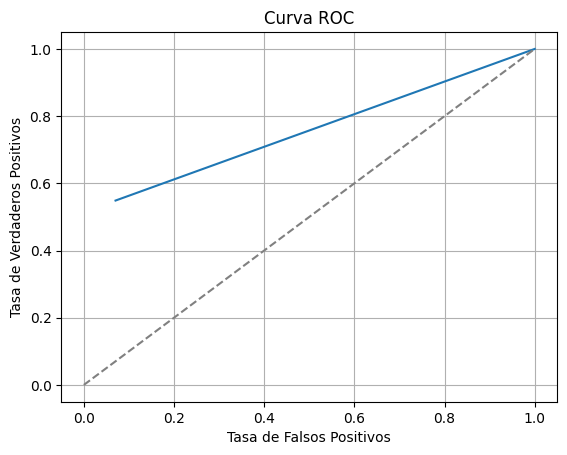

In [75]:
leaf2_df3['TPR'] = leaf2_df3['TP'] / (leaf2_df3['TP'] + leaf2_df3['FN'])
leaf2_df3['FPR'] = leaf2_df3['FP'] / (leaf2_df3['FP'] + leaf2_df3['TN'])

sns.lineplot(x='FPR', y='TPR', data=leaf2_df3)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('Tasa de Falsos Positivos')
plt.ylabel('Tasa de Verdaderos Positivos')
plt.title('Curva ROC')
plt.grid(True)
plt.show()

# Nota: Es probable que los valores de FPR y TPR esten lejos del [0,0] y [1,1]
# si ese es su caso, debe agregarlos a mano a la tabla

In [55]:
leaf2_df3 = leaf2_df3[["prob_baja_2", "TP", "TN", "FP", "FN"]].copy()
leaf2_df3.sort_values("prob_baja_2", ascending=False, inplace=True)

leaf2_df3['sensibilidad'] = leaf2_df3['TP'] / (leaf2_df3['TP'] + leaf2_df3['FN'])
leaf2_df3['especificidad'] = leaf2_df3['TN'] / (leaf2_df3['TN'] + leaf2_df3['FP'])
leaf2_df3['accuracy'] = (leaf2_df3['TP'] + leaf2_df3['TN']) / (leaf2_df3['TP'] + leaf2_df3['TN'] + leaf2_df3['FP'] + leaf2_df3['FN'])
leaf2_df3['precision'] = leaf2_df3['TP'] / (leaf2_df3['TP'] + leaf2_df3['FP'])
leaf2_df3['f1'] = 2 * (leaf2_df3['precision'] * leaf2_df3['sensibilidad']) / (leaf2_df3['precision'] + leaf2_df3['sensibilidad'])

print("Máximo accuracy:", leaf2_df3.loc[leaf2_df3['accuracy'].idxmax(), ['prob_baja_2', 'accuracy']].to_dict())
print("Máxima sensibilidad:", leaf2_df3.loc[leaf2_df3['sensibilidad'].idxmax(), ['prob_baja_2', 'sensibilidad']].to_dict())
print("Máxima especificidad:", leaf2_df3.loc[leaf2_df3['especificidad'].idxmax(), ['prob_baja_2', 'especificidad']].to_dict())
print("Máximo F1:", leaf2_df3.loc[leaf2_df3['f1'].idxmax(), ['prob_baja_2', 'f1']].to_dict())

Máximo accuracy: {'prob_baja_2': 0.05195776872557985, 'accuracy': 0.9270106072854658}
Máxima sensibilidad: {'prob_baja_2': 0.003398234769098542, 'sensibilidad': 1.0}
Máxima especificidad: {'prob_baja_2': 0.05195776872557985, 'especificidad': 0.9296678898516759}
Máximo F1: {'prob_baja_2': 0.05195776872557985, 'f1': 0.09492709599027946}


In [74]:
temp_df = leaf2_df3.dropna(subset=['TP', 'TN', 'FP', 'FN']).copy()
temp_df['TPR'] = temp_df['TP'] / (temp_df['TP'] + temp_df['FN'])
temp_df['FPR'] = temp_df['FP'] / (temp_df['FP'] + temp_df['TN'])
np.trapezoid(temp_df['TPR'], temp_df['FPR'])

np.float64(0.7199008593934838)

## EDA
### Sumarizando

Empezamos por un pantallazo sobre todas las variables, con una **sumarización**, agregando 2 estadísticos muy importantes que no trae por defecto **Pandas**

* **Número de valores únicos de una variables**: Muchas veces variables categóricas están codificadas en variables numéricas. Este indicador nos ayudará a detectarlas
* **Número de missing values**: Que cantidad de registros tienen valores numéricos y cuales tiene faltantes. El tratamiento (o no) de missings es uno de los temas que navegarán en los **experimentos colectivos**

Navegue la tabla a la par de el **diccionario de datos**. Los alumnos tienen a subestimar el poder de entender el conjunto de datos a la hora de hacer un buen modelo.

In [56]:
desc_stats = data.describe(include='all') # Calcula estadísticas descriptivas básicas
missing_values = data.isnull().sum() # Calcula el número de valores faltantes por columna
unique_values = data.nunique() # Calcula el número de valores distintos por columna

# Combina las estadísticas en un solo DataFrame
summary_table = pd.DataFrame({
    'Missing Values': missing_values,
    'Unique Values': unique_values
})

pd.concat([summary_table.transpose(), desc_stats], axis=0).transpose()


,Missing Values,Unique Values,count,unique,top,freq,mean,std,min,25%,50%,75%,max
numero_de_cliente,0.0,163284.0,163284.0,NaN,NaN,NaN,37665648.152238,15780906.293389,12159854.0,25322583.75,35797950.0,48864749.0,77722076.0
foto_mes,0.0,1.0,163284.0,NaN,NaN,NaN,202104.0,0.0,202104.0,202104.0,202104.0,202104.0,202104.0
active_quarter,0.0,2.0,163284.0,NaN,NaN,NaN,0.986876,0.113808,0.0,1.0,1.0,1.0,1.0
cliente_vip,0.0,2.0,163284.0,NaN,NaN,NaN,0.002609,0.051011,0.0,0.0,0.0,0.0,1.0
internet,0.0,5.0,163284.0,NaN,NaN,NaN,0.06237,0.313295,0.0,0.0,0.0,0.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
Visa_cconsumos,21790.0,132.0,141494.0,NaN,NaN,NaN,8.160565,9.864165,0.0,2.0,5.0,11.0,180.0
Visa_cadelantosefectivo,21790.0,14.0,141494.0,NaN,NaN,NaN,0.008792,0.201397,0.0,0.0,0.0,0.0,16.0
Visa_mpagominimo,7987.0,5726.0,155297.0,NaN,NaN,NaN,6082.537715,18668.150809,0.0,586.5,2252.16,5618.67,2073101.55
mes_0,0.0,1.0,163284.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0


### Explorando las variables más importantes del modelo

Vamos a profundizar sobre las variables utilizadas por el modelo. Si las eligió el modelo, seguro nos ayudará a entender un poco más los datos, no?

Para este fin, vamos a obtener la importancia de variable del modelo

In [57]:
feature_importances = pd.DataFrame({'feature': X.columns, 'importance': model.feature_importances_})
feature_importances.sort_values('importance', ascending=False)


,feature,importance
107,ctrx_quarter,0.328366
111,Master_status,0.171747
22,mcuentas_saldo,0.154961
33,mprestamos_personales,0.104792
113,Master_Fvencimiento,0.094554
...,...,...
150,Visa_mconsumototal,0.000000
151,Visa_cconsumos,0.000000
152,Visa_cadelantosefectivo,0.000000
153,Visa_mpagominimo,0.000000


Tomaremos algunas para hacer un doble click

#### ctrx_quarter

**¿Qué significa esta variable?**

Cómo se trata de una variable numéricas, vamos a graficar la densidad por cada clase:

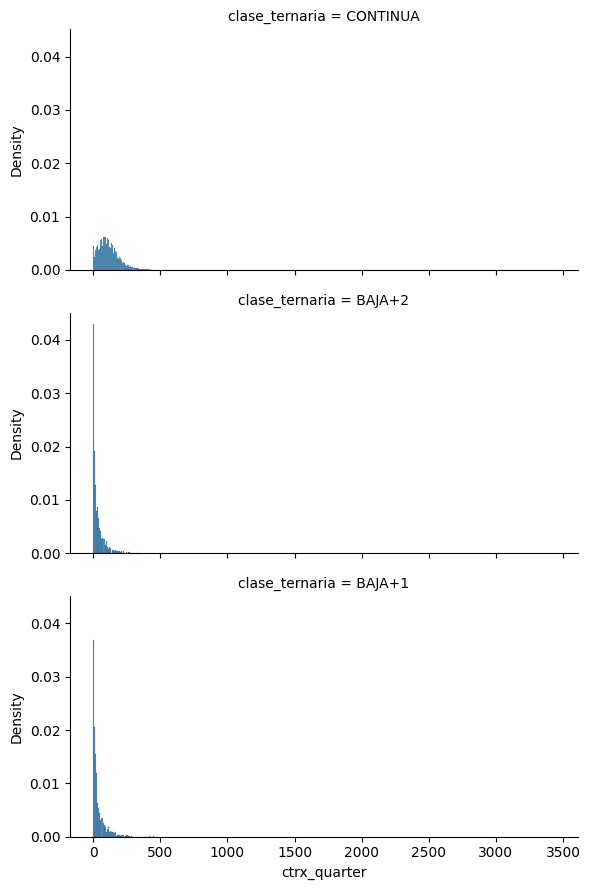

In [58]:
g = sns.FacetGrid(data, row="clase_ternaria", height=3, aspect=2)
g.map(sns.histplot, "ctrx_quarter", stat='density')

* **¿Qué conclusiones saca de los gráficos?**
* **¿Detecta algún patrón en la baja de los clientes?**

#### Visa_status

**¿Qué significa esta variable?**

Esta variable es númerica, pero tiene una baja cardinalidad. Vamos a estudiarla de otra manera

In [59]:
pd.crosstab(data['Visa_status'], data['clase_ternaria'])

clase_ternaria,BAJA+1,BAJA+2,CONTINUA
Visa_status,,,
0.0,641,787,153265
6.0,6,2,6
7.0,19,20,307
9.0,75,23,146


* **¿Qué conclusiones saca de esta tabla?**
* **¿Detecta algún patrón en la baja de los clientes?**

Podemos usar una regla de negocio para `Visa_status > 0`. Veamos algunas métricas de esta misma:

In [60]:
numero_clientes = data.shape[0]
cantidad_baja2 = data[data['clase_ternaria'] == 'BAJA+2'].shape[0]

cantidad_visa_gt_0 = data[data['Visa_status'] > 0].shape[0]
cantidad_visa_gt_0_and_baja2 = data[(data['Visa_status'] > 0) & (data['clase_ternaria'] == 'BAJA+2')].shape[0]

P_baja2 = cantidad_baja2 / numero_clientes

P_visa_status_gt_0_and_baja2 = (cantidad_visa_gt_0_and_baja2 / cantidad_visa_gt_0)

lift = P_visa_status_gt_0_and_baja2 / P_baja2

columnas = ["Métrica", "Valor"]
registros = [
    ("Total de clientes", f"{numero_clientes}"),
    ("P(Visa_status > 0 y BAJA+2)", f"{P_visa_status_gt_0_and_baja2:.6f}"),
    ("P(BAJA+2)", f"{P_baja2:.6f}"),
    ("Lift", f"{lift:.6f}")
]

pd.DataFrame(registros, columns=columnas)

,Métrica,Valor
0,Total de clientes,163284
1,P(Visa_status > 0 y BAJA+2),0.074503
2,P(BAJA+2),0.006976
3,Lift,10.680596


In [61]:
TP = cantidad_visa_gt_0_and_baja2
FN = cantidad_baja2 - TP
FP = cantidad_visa_gt_0 - TP

recall = TP / (TP + FN)

gain = (TP * ganancia_acierto) - (FP * costo_estimulo)

columnas = ["Métrica", "Valor"]
registros = [
    ["TP", f"{TP}"],
    ["FN", f"{FN}"],
    ["FP", f"{FP}"],
    ("Recall", f"{recall:.6f}"),
    ("Ganancia", f"{gain:,.0f} $"),
]
pd.DataFrame(registros, columns=columnas)

,Métrica,Valor
0,TP,45
1,FN,1094
2,FP,559
3,Recall,0.039508
4,Ganancia,"32,890,000 $"


#### mpasivos_margen

**¿Qué significa esta variable?**

Esta variable también es númerica. Intente gráficar un diagrama de densidad y verá que no es algo que vaya a funcionar muy bien.

Frente a un escenario así podemos recurrir a los todo poderosos **box-plots**

<Axes: xlabel='clase_ternaria', ylabel='mpasivos_margen'>

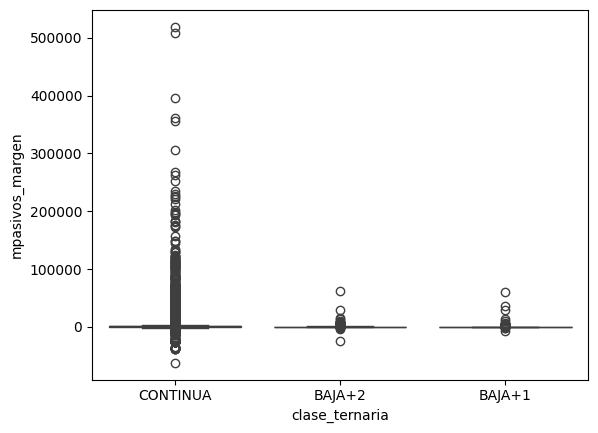

In [62]:
sns.boxplot(x='clase_ternaria', y='mpasivos_margen', data=data)

Ok... esto no es muy ilustrativo.

* **¿Qué son esos círculitos?**

Probemos podar un poco la variable:

<Axes: xlabel='clase_ternaria', ylabel='mpasivos_margen'>

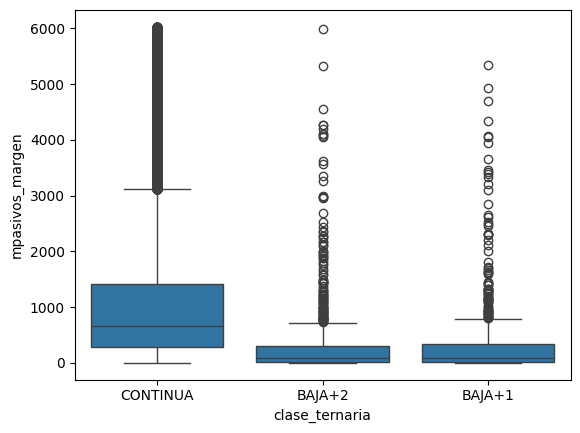

In [63]:
lower_bound = data['mpasivos_margen'].quantile(0.05)
upper_bound = data['mpasivos_margen'].quantile(0.95)

filtered_data = data[(data['mpasivos_margen'] >= lower_bound) & (data['mpasivos_margen'] <= upper_bound)]
sns.boxplot(x='clase_ternaria', y='mpasivos_margen', data=filtered_data)

* **¿Qué paso en el código anterior?**
* **¿Qué interpretación hace sobre el gráfico?**

### Tarea
Esto es solo el comienzo. Tiene que hacer un video a **Miranda** y para eso debe entender bien los datos. Continue con el **EDA**.

* Sume al análisis los periodos descartados
* ¿Se pueden construir features que den más luz a los modelos a detectar las futuras bajas?

Explore junto con su **agente** amigo en busca de nuevos _insights_ y compartalos en Zulip en **#Code>EDA**